In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Hyperparameters (Updated for TTUR) ---
num_epochs = 2000
batch_size = 128
latent_dim = 2

# TTUR: Different learning rates for Generator and Discriminator
lr_G = 0.0001 # Slower Generator
lr_D = 0.0004 # Faster Discriminator

I0000 00:00:1780493562.439836 1582600 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1780493562.471877 1582600 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1780493563.288243 1582600 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
def get_real_samples(batch_size):
    x = np.random.uniform(-1, 1, (batch_size, 1))
    y = x ** 2
    
    # DATA JITTER: Add a tiny amount of noise to the real data
    # This prevents the Discriminator from memorizing a perfect line
    x += np.random.normal(0, 0.05, x.shape)
    y += np.random.normal(0, 0.05, y.shape)
    
    return np.hstack((x, y)).astype(np.float32) 

# --- 2. Architecture (Warning-Free) ---
def build_generator():
    model = models.Sequential([
        layers.Input(shape=(latent_dim,)), 
        layers.Dense(64),
        layers.LeakyReLU(negative_slope=0.2), # Updated here
        layers.Dense(64),
        layers.LeakyReLU(negative_slope=0.2), # Updated here
        layers.Dense(2) 
    ])
    return model

def build_discriminator():
    model = models.Sequential([
        layers.Input(shape=(2,)), 
        layers.Dense(64),
        layers.LeakyReLU(negative_slope=0.2), # Updated here
        layers.Dense(64),
        layers.LeakyReLU(negative_slope=0.2), # Updated here
        layers.Dense(1, activation='sigmoid')
    ])
    return model

W0000 00:00:1780493564.051632 1582600 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Starting Training...
Epoch [100/2000] | D Loss: 1.4043 | G Loss: 0.7359


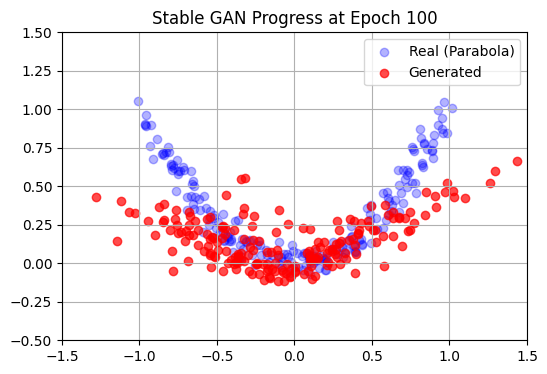

Epoch [200/2000] | D Loss: 1.3371 | G Loss: 0.9704


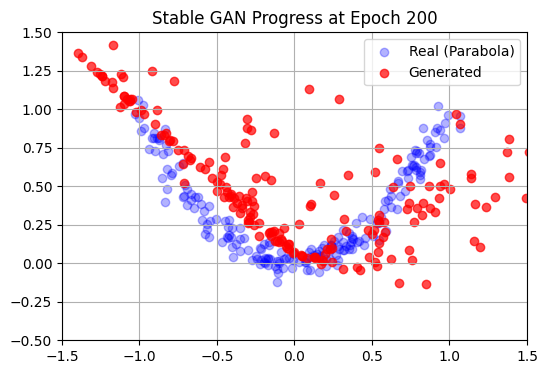

Epoch [300/2000] | D Loss: 1.3753 | G Loss: 0.7932


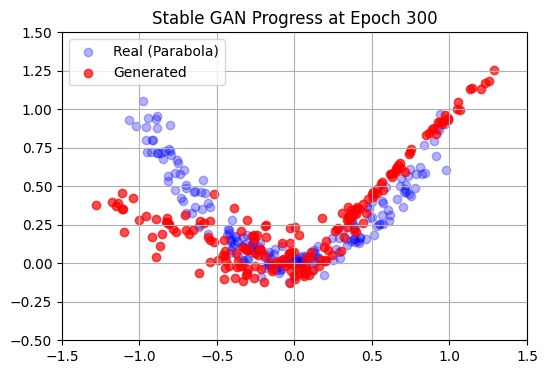

Epoch [400/2000] | D Loss: 1.3743 | G Loss: 0.8221


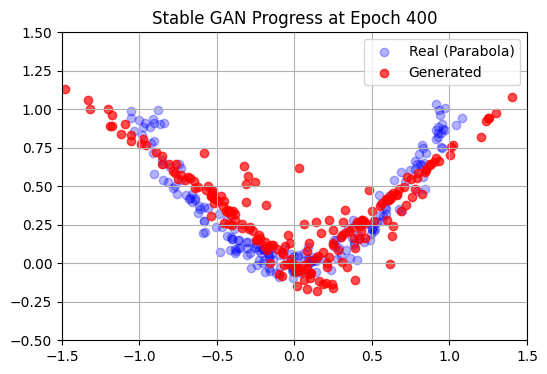

Epoch [500/2000] | D Loss: 1.3695 | G Loss: 0.8351


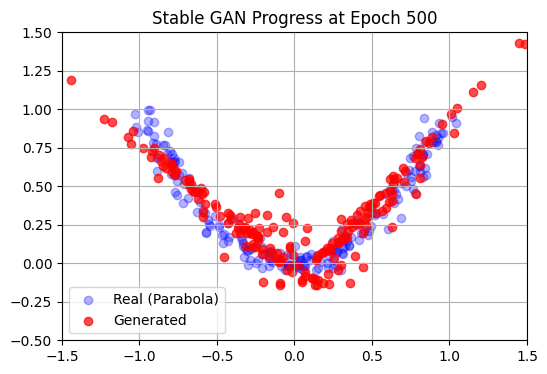

Epoch [600/2000] | D Loss: 1.3714 | G Loss: 0.8345


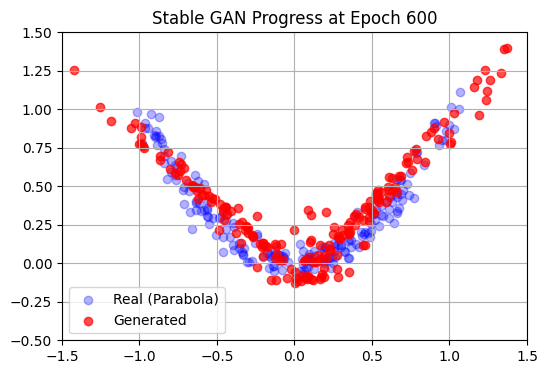

Epoch [700/2000] | D Loss: 1.3723 | G Loss: 0.8173


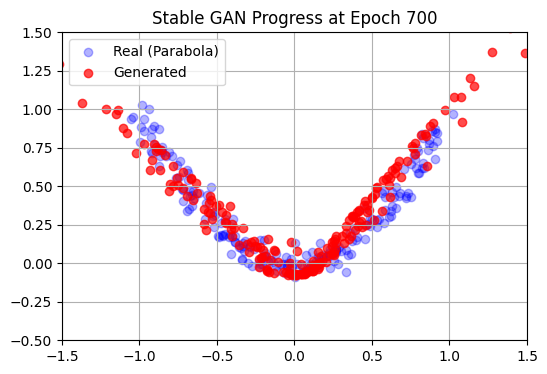

Epoch [800/2000] | D Loss: 1.3658 | G Loss: 0.8065


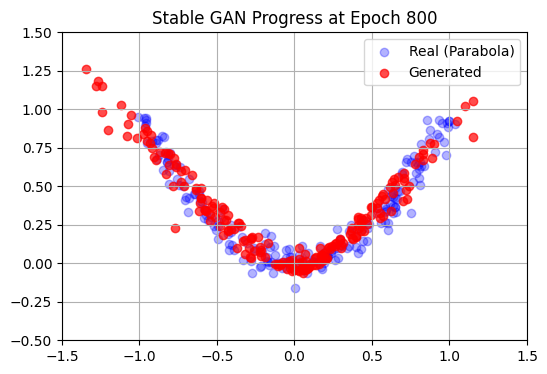

Epoch [900/2000] | D Loss: 1.3672 | G Loss: 0.7971


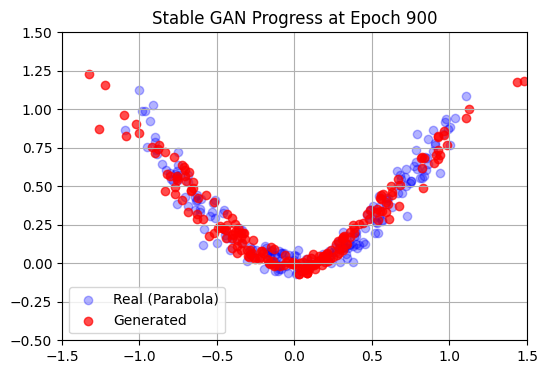

Epoch [1000/2000] | D Loss: 1.3715 | G Loss: 0.8011


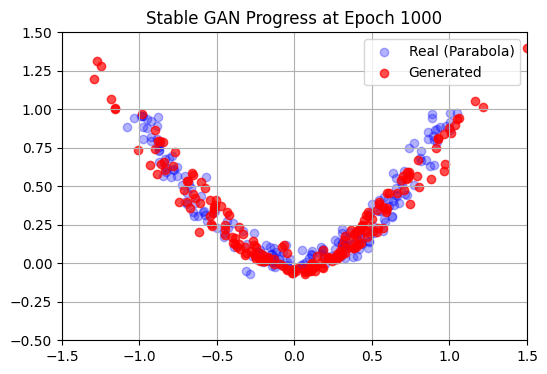

Epoch [1100/2000] | D Loss: 1.3714 | G Loss: 0.8026


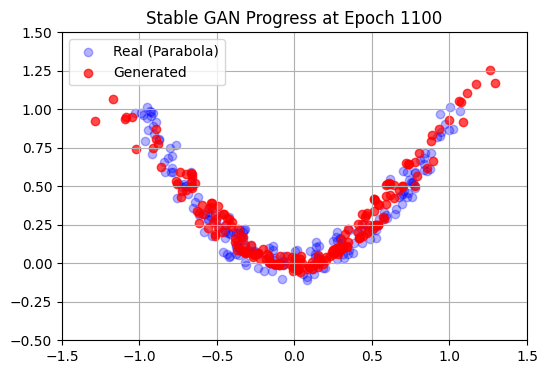

Epoch [1200/2000] | D Loss: 1.3653 | G Loss: 0.7912


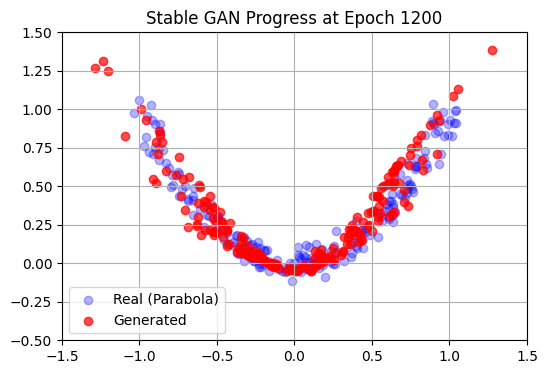

Epoch [1300/2000] | D Loss: 1.3573 | G Loss: 0.7744


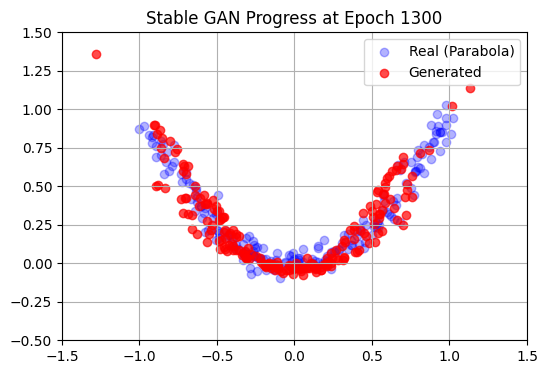

Epoch [1400/2000] | D Loss: 1.3708 | G Loss: 0.7501


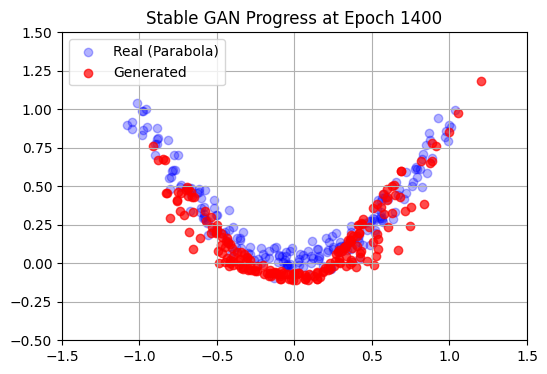

Epoch [1500/2000] | D Loss: 1.3790 | G Loss: 0.7887


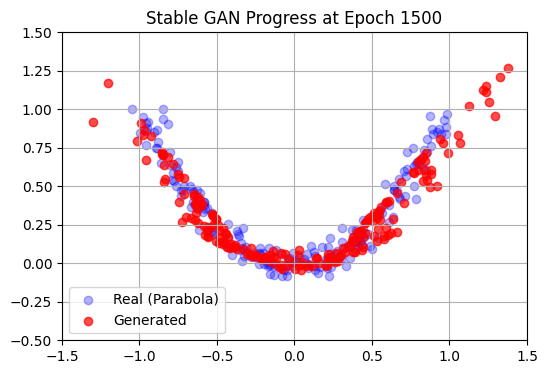

Epoch [1600/2000] | D Loss: 1.3665 | G Loss: 0.8819


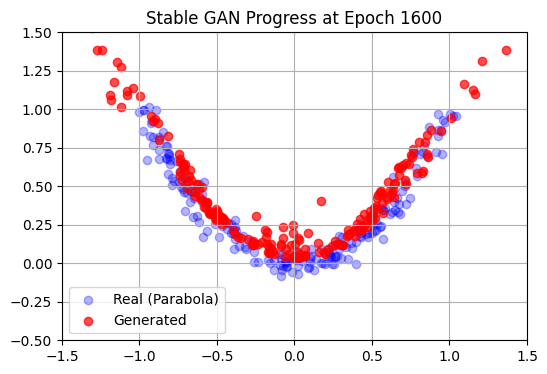

Epoch [1700/2000] | D Loss: 1.3871 | G Loss: 0.8169


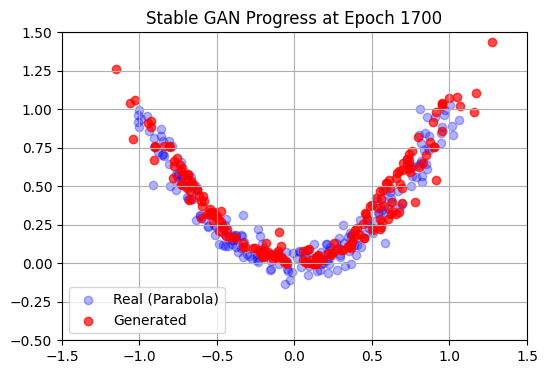

Epoch [1800/2000] | D Loss: 1.3615 | G Loss: 0.7937


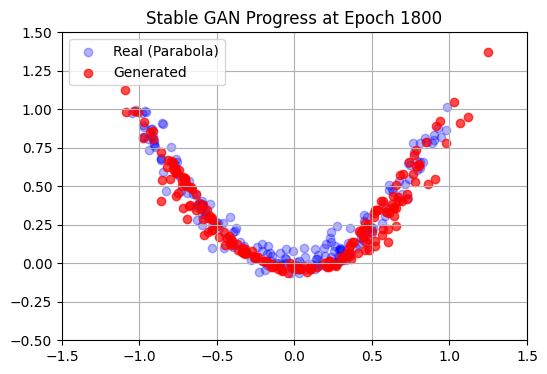

Epoch [1900/2000] | D Loss: 1.3646 | G Loss: 0.7847


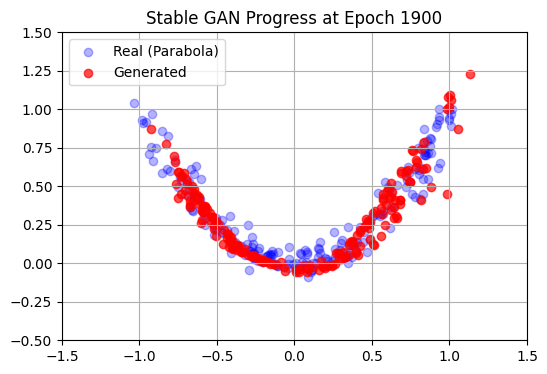

Epoch [2000/2000] | D Loss: 1.3763 | G Loss: 0.7829


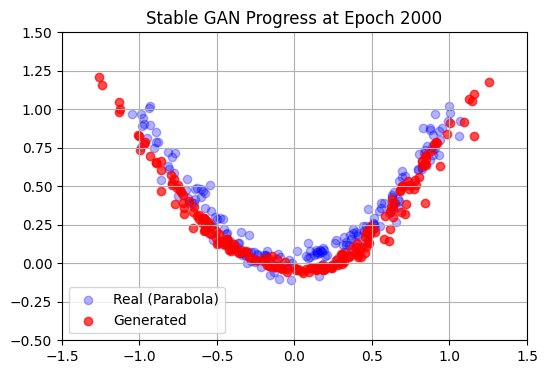

In [3]:
generator = build_generator()
discriminator = build_discriminator()

# --- 3. Setup Manual Optimizers ---
# Notice: No .compile() and no combined GAN model!
cross_entropy = tf.keras.losses.BinaryCrossentropy()
optimizer_G = optimizers.Adam(learning_rate=lr_G)
optimizer_D = optimizers.Adam(learning_rate=lr_D)

# --- 4. Custom Training Loop (GradientTape) ---
print("Starting Training...")
for epoch in range(num_epochs):
    
    # Generate Data
    real_data = get_real_samples(batch_size)
    noise = tf.random.normal([batch_size, latent_dim])
    
    # ---------------------
    #  Train Discriminator
    # ---------------------
    with tf.GradientTape() as tape_D:
        fake_data = generator(noise, training=False)
        real_output = discriminator(real_data, training=True)
        fake_output = discriminator(fake_data, training=True)
        
        # Calculate loss with LABEL SMOOTHING (0.9 instead of 1.0)
        d_loss_real = cross_entropy(tf.ones_like(real_output) * 0.9, real_output)
        d_loss_fake = cross_entropy(tf.zeros_like(fake_output), fake_output)
        d_loss = d_loss_real + d_loss_fake
        
    grads_D = tape_D.gradient(d_loss, discriminator.trainable_variables)
    optimizer_D.apply_gradients(zip(grads_D, discriminator.trainable_variables))
    
    # -----------------
    #  Train Generator
    # -----------------
    noise = tf.random.normal([batch_size, latent_dim])
    
    with tf.GradientTape() as tape_G:
        fake_data = generator(noise, training=True)
        fake_output = discriminator(fake_data, training=False)
        
        g_loss = cross_entropy(tf.ones_like(fake_output), fake_output)
        
    grads_G = tape_G.gradient(g_loss, generator.trainable_variables)
    optimizer_G.apply_gradients(zip(grads_G, generator.trainable_variables))

    # -------------------------
    #  Plot Progress over Time
    # -------------------------
    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}] | D Loss: {d_loss:.4f} | G Loss: {g_loss:.4f}")
        
        test_noise = tf.random.normal([200, latent_dim])
        current_generated_points = generator(test_noise, training=False).numpy()
        current_real_points = get_real_samples(200)

        plt.figure(figsize=(6, 4))
        plt.scatter(current_real_points[:, 0], current_real_points[:, 1], color='blue', alpha=0.3, label='Real (Parabola)')
        plt.scatter(current_generated_points[:, 0], current_generated_points[:, 1], color='red', alpha=0.7, label='Generated')
        plt.title(f"Stable GAN Progress at Epoch {epoch+1}")
        plt.xlim([-1.5, 1.5])
        plt.ylim([-0.5, 1.5])
        plt.legend()
        plt.grid(True)
        plt.show()

Training Complete! Generating final plot...


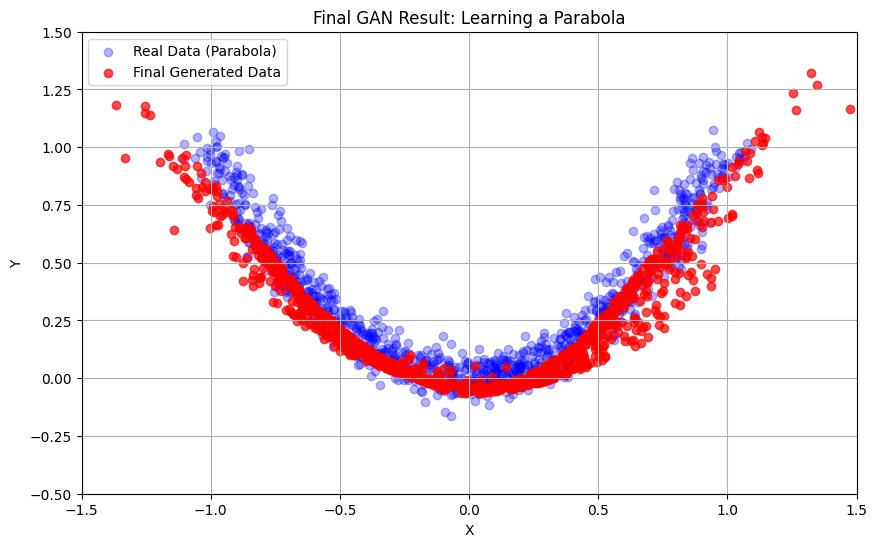

In [4]:
# --- 5. Final Visualization ---
print("Training Complete! Generating final plot...")

# Generate a larger set of fake data to see the final shape
final_noise = tf.random.normal([1000, latent_dim])
final_generated_points = generator(final_noise, training=False).numpy()

# Get a larger set of real data for comparison
final_real_points = get_real_samples(1000)

# Create the final high-resolution plot
plt.figure(figsize=(10, 6))
plt.scatter(final_real_points[:, 0], final_real_points[:, 1], color='blue', alpha=0.3, label='Real Data (Parabola)')
plt.scatter(final_generated_points[:, 0], final_generated_points[:, 1], color='red', alpha=0.7, label='Final Generated Data')
plt.title("Final GAN Result: Learning a Parabola")
plt.xlabel("X")
plt.ylabel("Y")

# Keep axis limits consistent
plt.xlim([-1.5, 1.5])
plt.ylim([-0.5, 1.5])

plt.legend()
plt.grid(True)
plt.show()